# 01 · Defining Churn

**Question:** when should we consider a Snabbit customer "churned"?

Customers never cancel; they just stop booking. So "churned" has to mean *silent for long
enough that they're probably not coming back*. Choosing "long enough" is a trade-off:

- **Too short** (e.g. 14 days): we label people who are just between bookings as churned.
  Retention spends money on customers who were coming back anyway, and the model learns noise.
- **Too long** (e.g. 180 days): labels are accurate but arrive so late that the customer is
  long gone before anyone acts.

**Approach:** answer it from behaviour, not intuition. Pick a past *snapshot date*, look at how
long each customer had been silent on that date, then check what they actually did next.

> ⚠️ **Synthetic data.** All numbers below come from the generated stand-in dataset.
> They show how the method works, not facts about Snabbit's customers. Re-run this notebook on
> real data before deciding anything.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import churn_definition as cd

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA = "../data/raw/synthetic/"
bookings = cd.load_bookings(DATA + "bookings.csv")

DATA_END = bookings["day"].max()
HORIZON = 180                                   # how far ahead we look for a return
SNAPSHOT = DATA_END - pd.Timedelta(days=HORIZON)  # latest date with a full 180-day future

print(f"{len(bookings):,} bookings, {bookings.customer_id.nunique():,} customers")
print(f"data ends {DATA_END.date()}, snapshot date {SNAPSHOT.date()}")

319,065 bookings, 18,426 customers
data ends 2026-10-31, snapshot date 2026-05-04


### What counts as "activity"?

We treat **any booking**, including ones the customer later cancelled, as a sign the customer is
still engaged. Making a booking shows intent even if the visit didn't happen. That's a
judgement call worth confirming with the Snabbit team once we see the real data.

## 1 · How often do customers normally book?

Before asking "how long is too long?", we need to know what normal looks like. The gap between
consecutive bookings of the same customer tells us that.

In [2]:
gaps = cd.add_gaps(bookings[bookings["day"] <= SNAPSHOT])
main_service = cd.customer_snapshot(bookings, SNAPSHOT)["main_service"]
gaps = gaps.dropna(subset=["gap_days"]).join(main_service, on="customer_id")

pct = gaps.groupby("main_service")["gap_days"].quantile([0.5, 0.8, 0.9, 0.95]).unstack()
pct.columns = ["median", "p80", "p90", "p95"]
pct.loc["ALL"] = gaps["gap_days"].quantile([0.5, 0.8, 0.9, 0.95]).values
pct.round(0)

,median,p80,p90,p95
main_service,,,,
bathroom_cleaning,26.0,45.0,64.0,87.0
cleaning,9.0,15.0,21.0,28.0
deep_cleaning,68.0,120.0,154.0,196.0
dishwashing,5.0,9.0,12.0,16.0
laundry,9.0,15.0,21.0,28.0
ALL,8.0,14.0,21.0,31.0


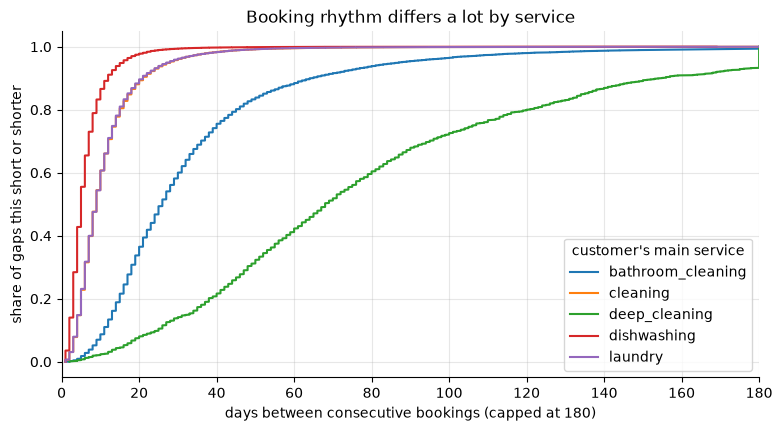

In [3]:
fig, ax = plt.subplots()
for svc, g in gaps.groupby("main_service"):
    x = np.sort(g["gap_days"].clip(upper=180))
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=svc)
ax.set(xlabel="days between consecutive bookings (capped at 180)",
       ylabel="share of gaps this short or shorter",
       title="Booking rhythm differs a lot by service", xlim=(0, 180))
ax.legend(title="customer's main service")
plt.show()

**How to read it:** where a curve reaches 0.9, 90% of that service's gaps are shorter than that.
(Cleaning is hidden behind laundry: the generator gave them the same weekly rhythm.)
Dishwashing customers almost always come back within about two weeks; deep-cleaning
customers routinely wait months. That's the first hint that **one inactivity cutoff for
everyone may be unfair to some services**.

## 2 · Once silent for *X* days, how many come back?

This is the core analysis. On the snapshot date we measure each customer's **recency** (days since
their last booking), then check whether they booked again in the following 180 days.

Note that this uses **only information the real database will also have**. No answer key needed.

In [4]:
snap = cd.customer_snapshot(bookings, SNAPSHOT)
snap["returned"] = cd.returned_within(snap, bookings, SNAPSHOT, HORIZON)

bins = [0, 7, 14, 21, 30, 45, 60, 90, 120, 180, 270, 365, 10_000]
snap["recency_bin"] = pd.cut(snap["recency_days"], bins, right=False)

curve = snap.groupby("recency_bin", observed=True)["returned"].agg(return_rate="mean", customers="size")
curve

,return_rate,customers
recency_bin,,
"[0, 7)",0.961,3763
"[7, 14)",0.903,1648
"[14, 21)",0.814,834
"[21, 30)",0.704,629
"[30, 45)",0.510,663
"[45, 60)",0.384,477
"[60, 90)",0.255,772
"[90, 120)",0.153,633
"[120, 180)",0.071,1160


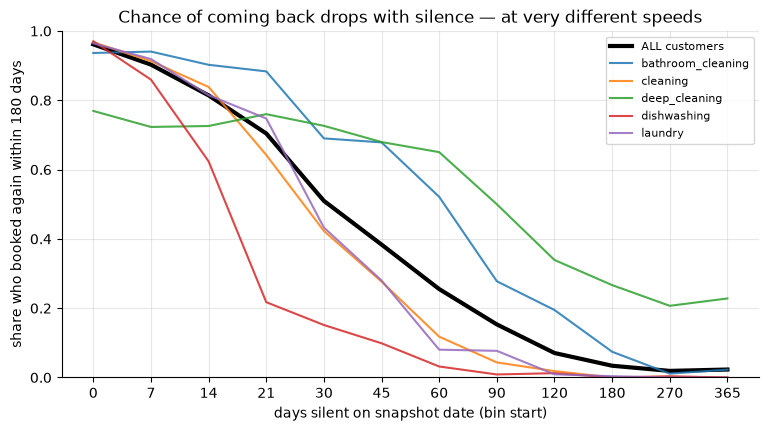

In [5]:
by_svc = snap.pivot_table(index="recency_bin", columns="main_service", values="returned",
                          aggfunc="mean", observed=True)
labels = [str(i.left) for i in curve.index]

fig, ax = plt.subplots()
ax.plot(labels, curve["return_rate"], color="black", lw=3, label="ALL customers")
for svc in by_svc:
    ax.plot(labels, by_svc[svc], lw=1.5, alpha=0.85, label=svc)
ax.set(xlabel="days silent on snapshot date (bin start)",
       ylabel="share who booked again within 180 days",
       title="Chance of coming back drops with silence — at very different speeds", ylim=(0, 1))
ax.legend(fontsize=8)
plt.show()

**How to read it:** a good churn cutoff sits where the curve has dropped low, so few labeled
"churned" customers would actually have come back. For dishwashing that happens within about
a month. For deep cleaning, more than half of customers silent for 60–90 days still come back.

## 3 · Measuring silence relative to each customer's own rhythm

Instead of fixed days, we can ask: *how many of their usual gaps has this customer missed?*
We use the customer's median gap if they have 3+ bookings, otherwise the norm for their main
service. Both are computed only from data up to the snapshot date.

In [6]:
svc_gaps = cd.service_typical_gaps(bookings, SNAPSHOT)
snap["typical_gap"] = cd.typical_gap(snap, svc_gaps)
snap["gaps_missed"] = snap["recency_days"] / snap["typical_gap"]

ratio_bins = [0, 1, 2, 3, 4, 6, 8, 12, np.inf]
rel = (snap.groupby(pd.cut(snap["gaps_missed"], ratio_bins, right=False), observed=True)["returned"]
           .agg(return_rate="mean", customers="size"))
rel

,return_rate,customers
gaps_missed,,
"[0.0, 1.0)",0.911,5417
"[1.0, 2.0)",0.799,1990
"[2.0, 3.0)",0.494,731
"[3.0, 4.0)",0.302,477
"[4.0, 6.0)",0.162,692
"[6.0, 8.0)",0.065,495
"[8.0, 12.0)",0.027,786
"[12.0, inf)",0.005,3219


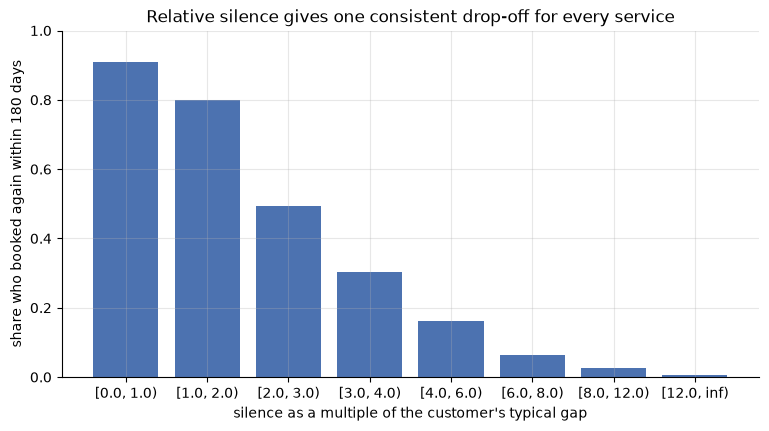

In [7]:
fig, ax = plt.subplots()
ax.bar([str(i) for i in rel.index], rel["return_rate"], color="#4C72B0")
ax.set(xlabel="silence as a multiple of the customer's typical gap",
       ylabel="share who booked again within 180 days",
       title="Relative silence gives one consistent drop-off for every service", ylim=(0, 1))
plt.show()

## 4 · Comparing candidate definitions

For each rule we label customers on the snapshot date, then score the labels against what happened
next. "Didn't return within 180 days" is our observable stand-in for *really gone*.

| Metric | Business meaning |
|---|---|
| **flagged** | Share of customers the rule calls churned |
| **precision** | Of those flagged, how many really didn't come back. Low means wasted retention spend. |
| **recall** | Of all who didn't come back, how many the rule caught. Low means missed customers. |

In [8]:
def score(flag, gone):
    tp = (flag & gone).sum()
    return {"flagged": flag.mean(), "precision": tp / flag.sum(), "recall": tp / gone.sum()}

rules = {f"fixed {d}d": cd.churned_fixed(snap, d) for d in (30, 45, 60, 90)}
for k in (3, 4, 5):
    rules[f"relative {k}x gap (min 30d)"] = cd.churned_relative(snap, svc_gaps, k, floor_days=30)

gone_observed = ~snap["returned"]
comparison = pd.DataFrame({name: score(flag, gone_observed) for name, flag in rules.items()}).T
comparison

,flagged,precision,recall
fixed 30d,0.502,0.858,0.902
fixed 45d,0.454,0.897,0.853
fixed 60d,0.420,0.920,0.808
fixed 90d,0.364,0.947,0.721
relative 3x gap (min 30d),0.403,0.949,0.800
relative 4x gap (min 30d),0.374,0.967,0.756
relative 5x gap (min 30d),0.349,0.977,0.713


### Where does each rule go wrong?

Overall scores can hide a group where a rule fails badly. Here is the precision of the leading
candidates, broken down by the customer's main service.

In [9]:
per_service = {}
for name in ("fixed 45d", "fixed 60d", "relative 3x gap (min 30d)"):
    flag = rules[name]
    per_service[name] = (gone_observed[flag]).groupby(snap.loc[flag, "main_service"]).mean()
per_service = pd.DataFrame(per_service)
per_service["customers"] = snap["main_service"].value_counts()
per_service

,fixed 45d,fixed 60d,relative 3x gap (min 30d),customers
main_service,,,,
bathroom_cleaning,0.755,0.805,0.875,1773
cleaning,0.960,0.978,0.962,5562
deep_cleaning,0.583,0.616,0.753,1078
dishwashing,0.987,0.993,0.982,2741
laundry,0.961,0.979,0.962,2653


## 5 · Synthetic-only check: does the observable score match the truth?

Our generator recorded when each customer *really* decided to leave. Real data won't have this.
We use it once here to check something important: **if the 180-day "didn't return" proxy agrees
with the truth, we can trust that proxy on real data**, where it's all we'll have.

In [10]:
truth = pd.read_csv(DATA + "_ground_truth.csv", parse_dates=["true_churn_date"]).set_index("customer_id")
gone_truth = truth["true_churn_date"].reindex(snap.index).le(SNAPSHOT)

check = pd.DataFrame({
    name: {**{f"{k} (observed)": v for k, v in score(flag, gone_observed).items() if k != "flagged"},
           **{f"{k} (truth)": v for k, v in score(flag, gone_truth).items() if k != "flagged"}}
    for name, flag in rules.items()
}).T
check

,precision (observed),recall (observed),precision (truth),recall (truth)
fixed 30d,0.858,0.902,0.841,0.906
fixed 45d,0.897,0.853,0.881,0.859
fixed 60d,0.920,0.808,0.905,0.815
fixed 90d,0.947,0.721,0.935,0.729
relative 3x gap (min 30d),0.949,0.800,0.945,0.817
relative 4x gap (min 30d),0.967,0.756,0.964,0.773
relative 5x gap (min 30d),0.977,0.713,0.974,0.729


## 6 · Conclusions (synthetic data, provisional)

**1. There is no single "correct" threshold, only a trade-off.** Going from 30 to 90 days raises
precision (85.8% → 94.7%) but lowers recall (90.2% → 72.1%). Shorter cutoffs catch more
leavers but mislabel more people who were just between bookings.

**2. Among fixed rules, 45–60 days is the sensible range.** That's where the return curve has
flattened (only about 25–38% of customers silent that long come back) and both precision and recall stay
above 80%.

**3. A fixed rule breaks down for infrequent services.** For cleaning, dishwashing and laundry a
60-day rule is about 98% precise. For **deep cleaning it's about 62%**, and bathroom cleaning about 80%.
Those customers routinely go months between bookings.

**4. Measuring silence against each customer's own rhythm is the better rule.** "Silent for 3× their
typical gap (and at least 30 days)" is **94.9% precise vs 92.0%** for 60 days fixed, at about the
same recall (80.0% vs 80.8%). Nearly all of the gain comes from infrequent services:
deep cleaning 62% → 75%, bathroom cleaning 80% → 88%. For frequent services the two rules are
equivalent.

**Provisional decision:** for version 1 we use the simple **60-day rule on frequent services only**,
where it's just as good (see notebook 02). The relative rule is the way to bring deep and bathroom
cleaning customers in later.

**5. A note on how this was found.** An earlier version of this notebook contained a bug: the
"typical gap per service" was grouped by each *booking's* service instead of the *customer's main
service*. That set deep cleaning's typical gap to about 9 days instead of about 70 and hid the
relative rule's advantage. Lesson: check intermediate numbers against common sense
(a 9-day deep-cleaning rhythm should have been a red flag) before trusting a comparison.

**6. Our observable check can be trusted.** In section 5, scores against "didn't return in 180
days" are within about 1.5 points of scores against the true answer key for every rule. On real
data, where no answer key exists, this same method should give a reliable comparison.

### To confirm with Snabbit before finalising
- Do cancelled bookings count as activity?
- Is there an existing "lapsed customer" definition we should align with?
- How do they want infrequent services (deep cleaning) handled?
- How early does the retention team need to act? (This sets the prediction horizon; see notebook 02.)
